<a href="https://colab.research.google.com/github/Sucharitha255/Gen-AI-Practise/blob/main/Experiment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q tensorflow medmnist matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 1.3 MB/s eta 0:00:00


100%|██████████| 4.17M/4.17M [00:08<00:00, 465kB/s]


Dataset shape: (4708, 28, 28, 1)
Number of training images: 4708


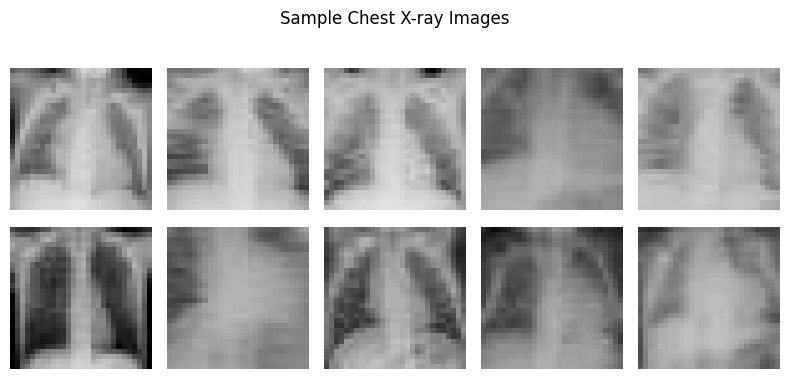

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import medmnist

from medmnist import PneumoniaMNIST
from tensorflow.keras import layers, Model

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load training images
dataset = PneumoniaMNIST(
    split="train",
    download=True,
    size=28
)

# Convert images to grayscale arrays
images = np.array(dataset.imgs)

if images.ndim == 4:
    images = images[..., 0]

images = images.astype("float32")
images = images[..., np.newaxis]

# Normalize pixels from [0, 255] to [-1, 1]
images = (images / 127.5) - 1.0

print("Dataset shape:", images.shape)
print("Number of training images:", len(images))

# Display sample real images
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i, :, :, 0], cmap="gray", vmin=-1, vmax=1)
    plt.axis("off")

plt.suptitle("Sample Chest X-ray Images")
plt.tight_layout()
plt.show()

In [3]:
def build_generator():
    model = tf.keras.Sequential([
        layers.Input(shape=(100,)),

        layers.Dense(7 * 7 * 128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 128)),

        layers.Conv2DTranspose(
            64, 4, strides=2, padding="same",
            use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(
            1, 4, strides=2, padding="same",
            activation="tanh"
        )
    ], name="Generator")

    return model


generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [4]:
def build_discriminator():
    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(
            64, 4, strides=2, padding="same"
        ),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(
            128, 4, strides=2, padding="same"
        ),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ], name="Discriminator")

    return model


discriminator = build_discriminator()
discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Training configuration
LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 10

dataset_tf = tf.data.Dataset.from_tensor_slices(images)
dataset_tf = (
    dataset_tf
    .shuffle(10000)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

# Binary cross-entropy with logits
loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)

g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)


@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(
            real_images, training=True
        )
        fake_output = discriminator(
            fake_images, training=True
        )

        # Discriminator wants real=1 and fake=0
        d_loss_real = loss_fn(
            tf.ones_like(real_output), real_output
        )
        d_loss_fake = loss_fn(
            tf.zeros_like(fake_output), fake_output
        )
        d_loss = d_loss_real + d_loss_fake

        # Generator wants fake images classified as real
        g_loss = loss_fn(
            tf.ones_like(fake_output), fake_output
        )

    g_gradients = gen_tape.gradient(
        g_loss, generator.trainable_variables
    )
    d_gradients = disc_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )
    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return g_loss, d_loss


# Train the models
for epoch in range(EPOCHS):
    g_losses = []
    d_losses = []

    for real_batch in dataset_tf:
        g_loss, d_loss = train_step(real_batch)
        g_losses.append(float(g_loss))
        d_losses.append(float(d_loss))

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {np.mean(g_losses):.4f} | "
        f"Discriminator Loss: {np.mean(d_losses):.4f}"
    )

Epoch 1/10 | Generator Loss: 0.8006 | Discriminator Loss: 1.0962
Epoch 2/10 | Generator Loss: 0.9247 | Discriminator Loss: 1.0449
Epoch 3/10 | Generator Loss: 0.9375 | Discriminator Loss: 1.2157
Epoch 4/10 | Generator Loss: 0.8039 | Discriminator Loss: 1.2119
Epoch 5/10 | Generator Loss: 0.7305 | Discriminator Loss: 1.2769
Epoch 6/10 | Generator Loss: 0.7629 | Discriminator Loss: 1.3130
Epoch 7/10 | Generator Loss: 0.7147 | Discriminator Loss: 1.3310
Epoch 8/10 | Generator Loss: 0.7076 | Discriminator Loss: 1.3596
Epoch 9/10 | Generator Loss: 0.7107 | Discriminator Loss: 1.3793
Epoch 10/10 | Generator Loss: 0.6951 | Discriminator Loss: 1.3839


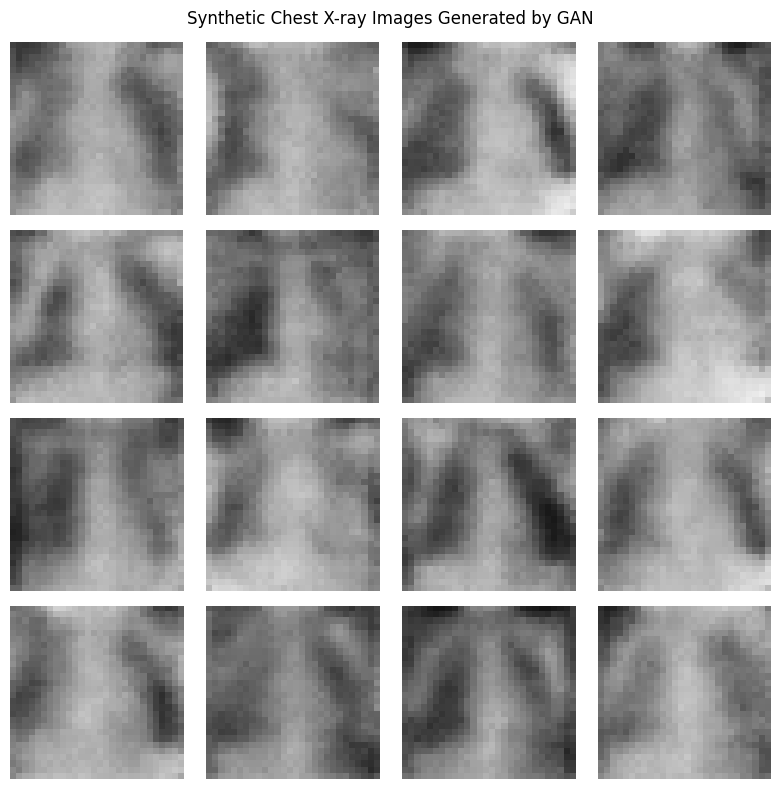

In [6]:
# Generate 16 synthetic images
num_images = 16

noise = tf.random.normal([num_images, LATENT_DIM])
synthetic_images = generator(noise, training=False)

# Convert pixel values from [-1, 1] to [0, 1]
synthetic_images = (synthetic_images + 1) / 2

# Visualize the generated images
plt.figure(figsize=(8, 8))

for i in range(num_images):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        synthetic_images[i, :, :, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.axis("off")

plt.suptitle("Synthetic Chest X-ray Images Generated by GAN")
plt.tight_layout()
plt.show()

In [7]:
import os

os.makedirs("synthetic_medical_images", exist_ok=True)

for i in range(num_images):
    image = synthetic_images[i, :, :, 0].numpy()

    plt.imsave(
        f"synthetic_medical_images/image_{i + 1}.png",
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

print("Synthetic images saved successfully!")

Synthetic images saved successfully!


In [8]:
generator_history = []
discriminator_history = []

In [ ]:
generator_history.append(np.mean(g_losses))
discriminator_history.append(np.mean(d_losses))

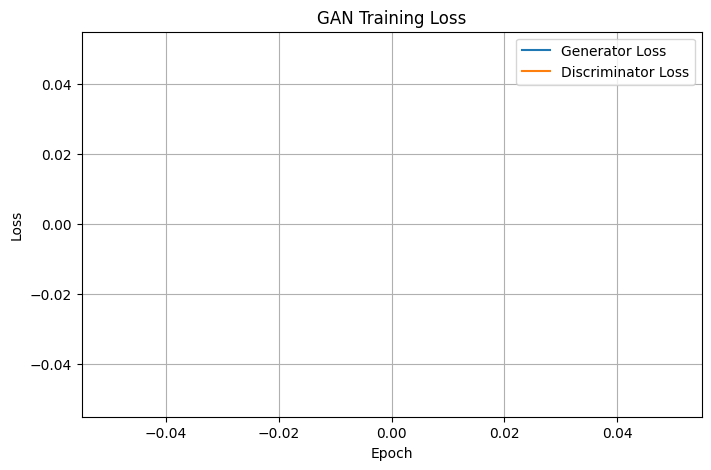

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(generator_history, label="Generator Loss")
plt.plot(discriminator_history, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()